## SST

In [ ]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [1]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

import sys
from pathlib import Path
import os

from scipy.io import loadmat
from helper import plot_training_curves, evaluate_model, plot_reconstruction

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))
DATA_DIR = Path.cwd() / "datasets"  

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Exploration

Shape of X_raw: (9490, 64800) after permutation: 
[15  2 10 14 12 20 18 16 23  4  6 13  0  7  8  1  3 11 22  5 25 19 21 17
  9 24]
Shape of X_raw: (9490, 64800)
Shape of X_clean: (9490, 41027)
Shape of sensor locations: (9490, 10)


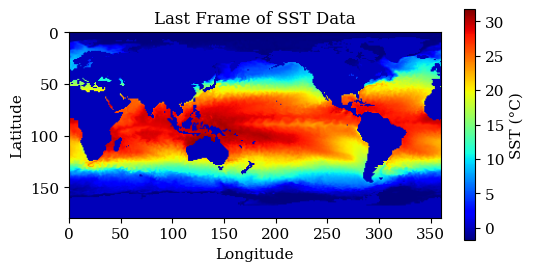

In [55]:
# Load SST data -> X RAW
X_raw = np.load(DATA_DIR / "sst_all_ROM.npy")
#shuffle the data along the year axis
permutation = np.random.permutation(X_raw.shape[0])
X_raw = X_raw[permutation]
X_raw = X_raw.reshape(-1, 180 * 360)  
print(f"Shape of X_raw: {X_raw.shape} after permutation: \n{permutation}")

# Load SST data -> X CLEAN
mean_X = np.mean(X_raw, axis=0)
sst_locs = np.where(mean_X != 0)[0]
X_clean = X_raw[:, sst_locs]

# Extract sensor locations and number of sensors
num_sensors = 10
sensor_locations = np.random.choice(X_clean.shape[1], size=num_sensors, replace=False)
sensor = X_clean[:, sensor_locations]

# Print shapes of the datasets
print(f"Shape of X_raw: {X_raw.shape}")
print(f"Shape of X_clean: {X_clean.shape}")
print(f"Shape of sensor locations: {sensor.shape}")

# Plot the last frame of the data
plt.figure(figsize=(6, 3))
plt.imshow(X_raw[-1, :].reshape(180, 360), cmap='jet')
plt.colorbar(label='SST (°C)')
plt.title('Last Frame of SST Data')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [56]:
ERRORS = []

# DataManager
LAGS = 26

TRAIN_SIZE = 0.70        # percentage of data used for training 
VAL_SIZE = 0.15          # percentage of data used for validation
TEST_SIZE = 0.15         # percentage of data used for testing

COMPRESS_SST = 1000

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 400        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [256]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## Dataloader

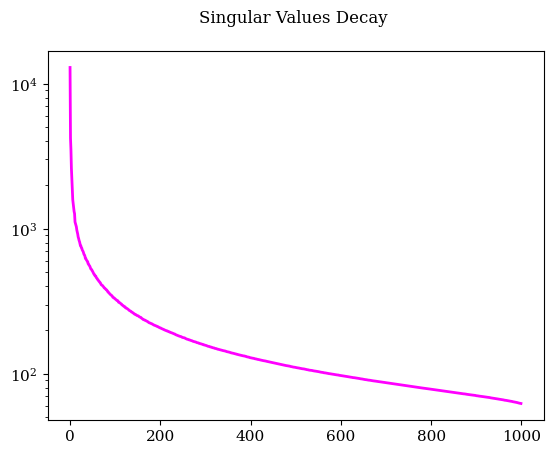

Residual energy of Surface elevation after keeping 1000 modes: 1.3319 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([6643, 26, 10]) -> torch.Size([6643, 1000])
Val:	 torch.Size([1423, 26, 10]) -> torch.Size([1423, 1000])
Test:	 torch.Size([1424, 26, 10]) -> torch.Size([1424, 1000])

Input shape for the model: 10
Output shape for the model: 1000


In [57]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(X_clean, id="Surface elevation", compress=COMPRESS_SST, measurements=sensor, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

## MODEL

Starting training...


Training:  31%|███       | 123/400 [01:55<04:20,  1.06it/s, Train Loss=0.01560, Val Loss=0.01557, Patience=79, Best Val Loss=0.01543, LR=3.91e-04]

Early stopping at epoch 124
Training completed with best validation loss: 0.0154


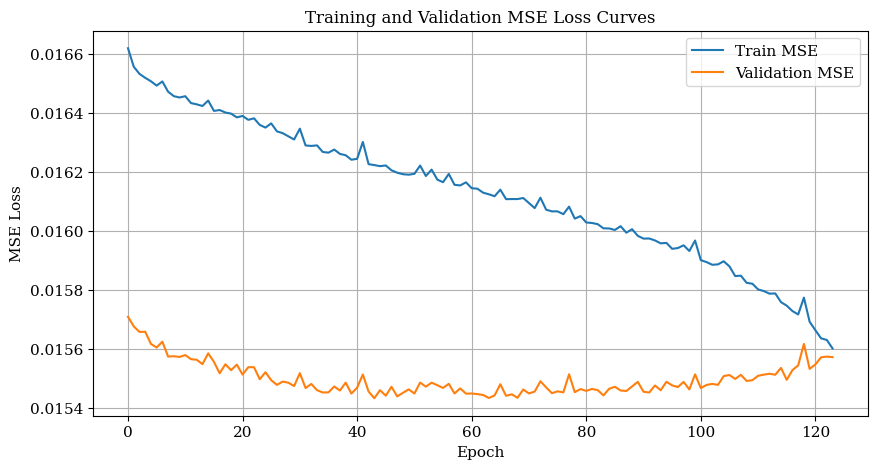

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.A): masking,0.016224,0.015433,0.014042,0.260694,0.254028,0.244113


In [58]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("outputs/dataframe_errors.csv", index=False)

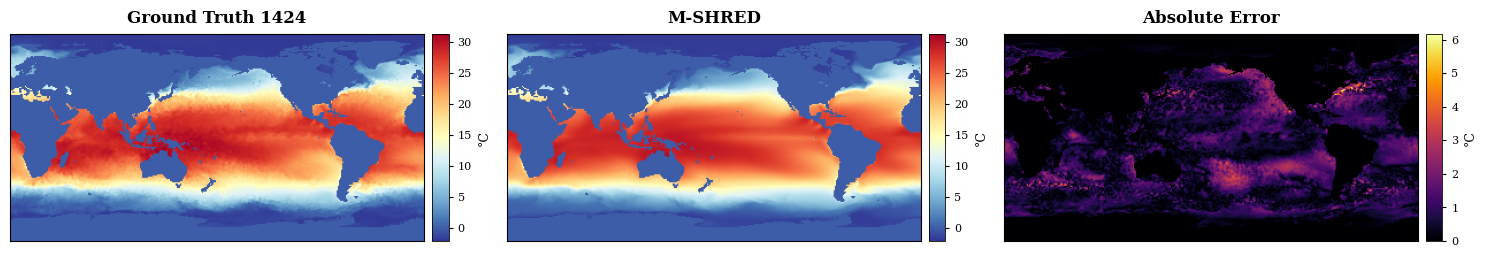

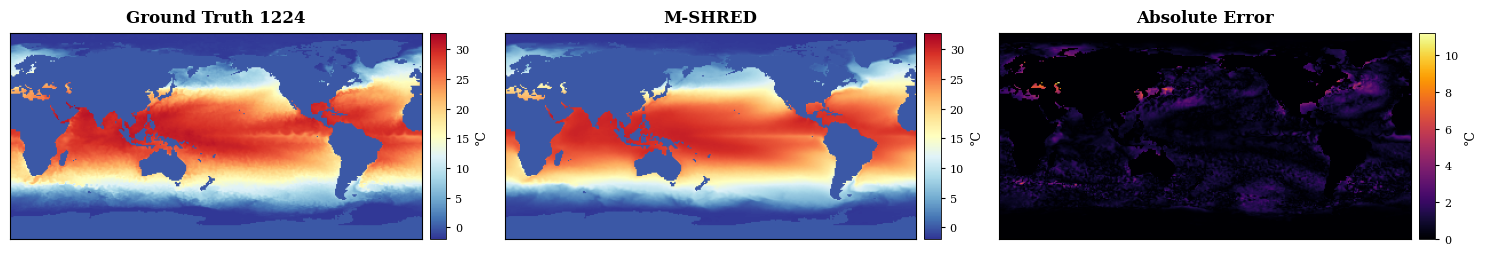

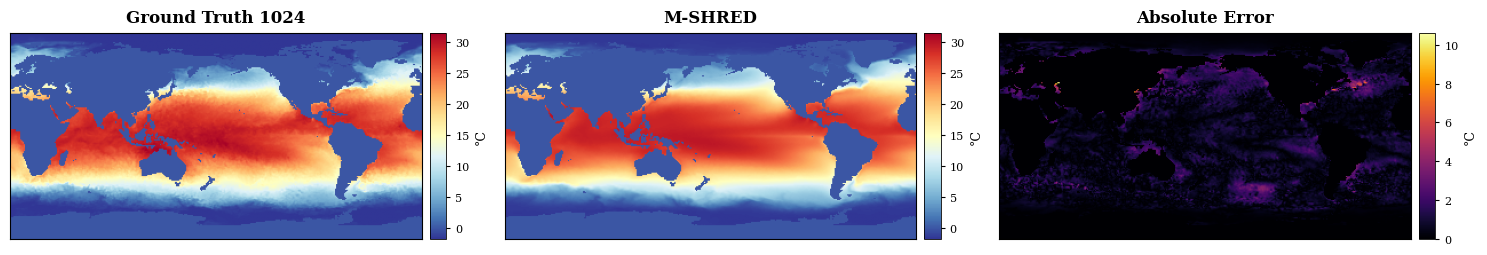

In [63]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)